# Fundamentals of Data Science — Case Study 4: Student Data and Performance

**Student:** Annika Reddy  
**Roll Number:** 160124733153  
**Random seed:** 7

This notebook explores student outcomes, compares first-semester grades across outcomes, conducts the Kruskal–Wallis test and evaluates logistic-regression baselines.

## 1. Setup and dataset loading

The UCI student dropout and academic success dataset is semicolon-separated. This notebook downloads it from UCI; an internet connection is required.

In [1]:
import io, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Report specifies fixed random seed 7.
RANDOM_STATE = 7
OUTPUT_DIR = "outputs"
from pathlib import Path
Path(OUTPUT_DIR).mkdir(exist_ok=True)


In [2]:
# Load the supplied semicolon-separated student dataset from the same folder.
from pathlib import Path
data_path = Path("Studentdata(1).csv")
if not data_path.exists():
    from google.colab import files
    uploaded = files.upload()
    data_path = Path("Studentdata(1).csv")
students = pd.read_csv(data_path, sep=";")
print("Dataset loaded:", data_path.name, "| shape:", students.shape)
students.head()

Dataset loaded: Studentdata(1).csv | shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Dataset quality and outcome distribution

Check dataset dimensions, missing values, duplicates and the distribution of the three final outcome classes.

,Metric,Value
0,Rows,4424
1,Columns,37
2,Missing cells,0
3,Duplicate rows,0
4,Target classes,3


,Count
Outcome,
Graduate,2209
Dropout,1421
Enrolled,794


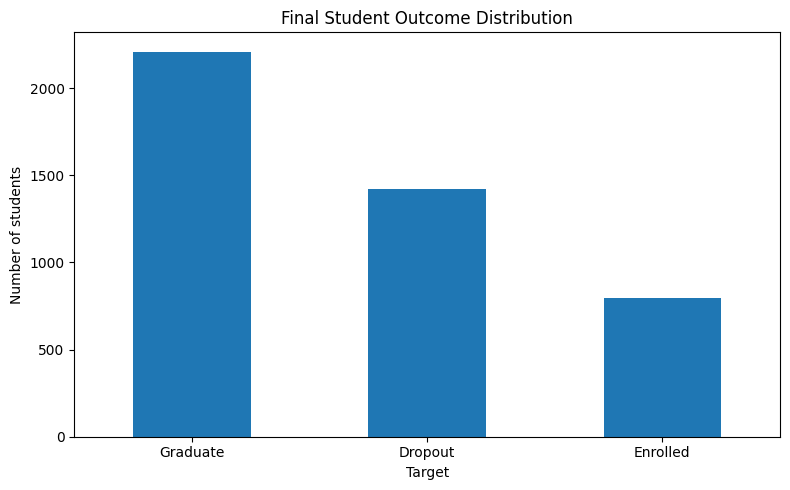

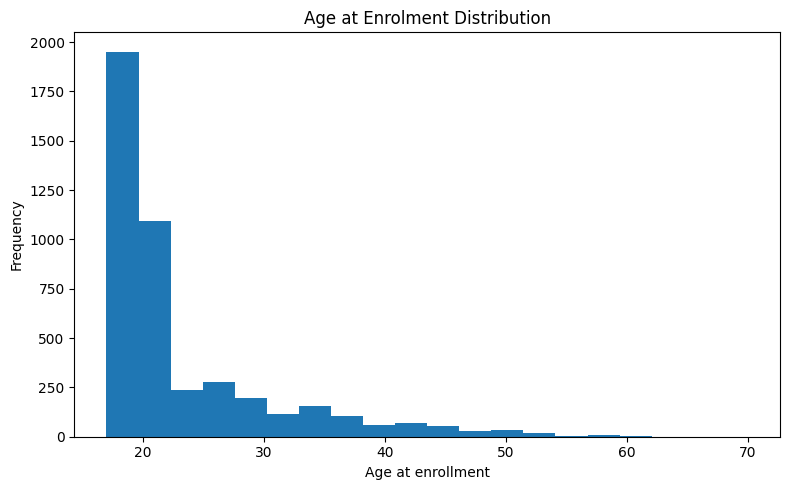

In [3]:
# Dataset structure and quality checks.
quality = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells", "Duplicate rows", "Target classes"],
    "Value": [len(students), students.shape[1], int(students.isna().sum().sum()),
              int(students.duplicated().sum()), students["Target"].nunique()]
})
display(quality)
quality.to_csv(f"{OUTPUT_DIR}/student_data_quality.csv", index=False)
display(students["Target"].value_counts().rename_axis("Outcome").to_frame("Count"))
target_counts = students["Target"].value_counts()
target_counts.plot(kind="bar", figsize=(8, 5), title="Final Student Outcome Distribution")
plt.ylabel("Number of students"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/student_target_distribution.png", dpi=200); plt.show()
students["Target"].value_counts().rename_axis("Target").reset_index(name="Count").to_csv(
    f"{OUTPUT_DIR}/student_target_distribution.csv", index=False)

if "Age at enrollment" in students.columns:
    students["Age at enrollment"].plot(kind="hist", bins=20, figsize=(8, 5),
                                      title="Age at Enrolment Distribution")
    plt.xlabel("Age at enrollment"); plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/student_age_distribution.png", dpi=200); plt.show()
students.select_dtypes(include="number").describe().T.to_csv(
    f"{OUTPUT_DIR}/student_numeric_summary.csv")


## 3. Exploratory analysis and hypothesis test

The Kruskal–Wallis test compares grade distributions across outcome groups. A small p-value indicates evidence that at least one group differs; it does not identify which pairs differ.

,count,mean,median,std
Target,,,,
Dropout,1421,7.257,10.929,6.031
Enrolled,794,11.125,12.000,3.675
Graduate,2209,12.644,13.000,2.699


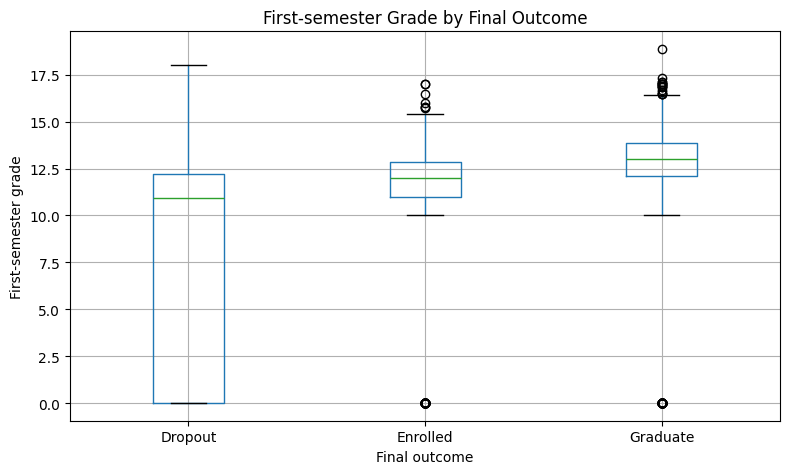

,H statistic,p-value,epsilon-squared,Significant at 0.05
0,1094.186486,2.514338e-238,0.247045,True


In [4]:
from scipy.stats import kruskal

grade_col = "Curricular units 1st sem (grade)"
if grade_col in students.columns:
    grade_summary = students.groupby("Target")[grade_col].agg(
        ["count", "mean", "median", "std"]).round(3)
    display(grade_summary)
    grade_summary.to_csv(f"{OUTPUT_DIR}/student_grade_by_outcome.csv")
    students.boxplot(column=grade_col, by="Target", figsize=(8, 5))
    plt.title("First-semester Grade by Final Outcome"); plt.suptitle("")
    plt.xlabel("Final outcome"); plt.ylabel("First-semester grade")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/student_grade_by_outcome.png", dpi=200); plt.show()
    groups = [g[grade_col].dropna().values for _, g in students.groupby("Target")]
    H, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    k = len(groups)
    epsilon_sq = max(0, (H-k+1)/(n-k))
    test_result = pd.DataFrame([{"H statistic": H, "p-value": p,
                                 "epsilon-squared": epsilon_sq,
                                 "Significant at 0.05": p < 0.05}])
    display(test_result)
    test_result.to_csv(f"{OUTPUT_DIR}/student_kruskal_wallis.csv", index=False)
else:
    print("Expected grade column was not found:", grade_col)


## 4. Logistic regression and model evaluation

The notebook compares standard logistic regression with a class-weighted model. Second-semester curricular-unit features are excluded to reduce target leakage for an early-prediction setting. The split is stratified, with 25% held out for testing.


 Standard logistic regression
              precision    recall  f1-score   support

     Dropout       0.74      0.75      0.75       355
    Enrolled       0.46      0.18      0.26       199
    Graduate       0.74      0.90      0.81       552

    accuracy                           0.72      1106
   macro avg       0.65      0.61      0.61      1106
weighted avg       0.69      0.72      0.69      1106



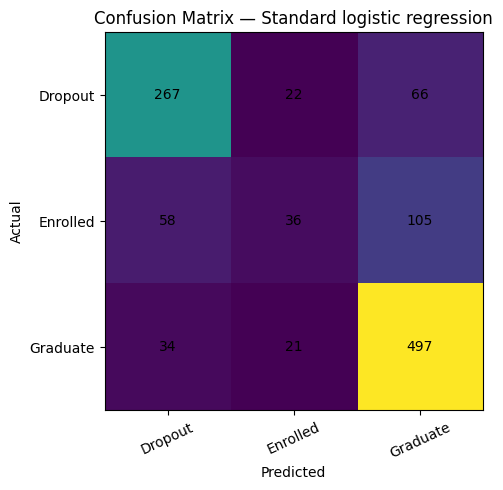


 Class-weighted logistic regression
              precision    recall  f1-score   support

     Dropout       0.81      0.66      0.73       355
    Enrolled       0.37      0.56      0.45       199
    Graduate       0.82      0.77      0.80       552

    accuracy                           0.70      1106
   macro avg       0.67      0.66      0.66      1106
weighted avg       0.74      0.70      0.71      1106



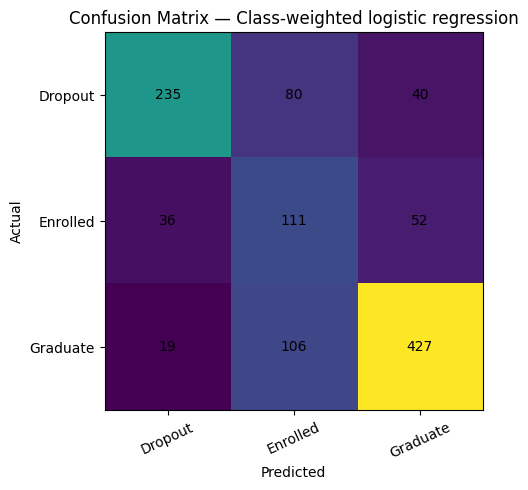

,Model,Accuracy,Balanced accuracy,Macro F1
0,Standard logistic regression,0.7233,0.6111,0.6072
1,Class-weighted logistic regression,0.6989,0.6644,0.6579


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

target_col = "Target"
y = students[target_col].astype(str)
X = students.drop(columns=[target_col]).copy()

# Exclude second-semester curricular-unit fields to reduce leakage
# for a model intended to predict outcomes earlier in a student's course.
second_sem_cols = [c for c in X.columns
                   if "2nd sem" in c.lower() or "2nd semester" in c.lower()]
X = X.drop(columns=second_sem_cols, errors="ignore")

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

models = {
    "Standard logistic regression": LogisticRegression(
        max_iter=3000, C=0.5, random_state=RANDOM_STATE),
    "Class-weighted logistic regression": LogisticRegression(
        max_iter=3000, C=0.5, class_weight="balanced", random_state=RANDOM_STATE)
}
results = {}
metric_rows = []
report_frames = []

for name, clf in models.items():
    model = Pipeline([("preprocess", preprocessor), ("classifier", clf)])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = (model, pred)
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0)
    })
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))
    report = pd.DataFrame(classification_report(
        y_test, pred, output_dict=True, zero_division=0)).T
    report["Model"] = name
    report_frames.append(report.reset_index(names="Class"))

    labels = model.named_steps["classifier"].classes_
    cm = confusion_matrix(y_test, pred, labels=labels)
    cm_df = pd.DataFrame(cm, index=[f"Actual {x}" for x in labels],
                         columns=[f"Predicted {x}" for x in labels])
    safe = name.lower().replace(" ", "_").replace("-", "_")
    cm_df.to_csv(f"{OUTPUT_DIR}/student_confusion_matrix_{safe}.csv")

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.imshow(cm)
    ax.set_title("Confusion Matrix — " + name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_xticks(range(len(labels)), labels=labels, rotation=25)
    ax.set_yticks(range(len(labels)), labels=labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/student_confusion_matrix_{safe}.png", dpi=200)
    plt.show()

metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))
metrics.to_csv(f"{OUTPUT_DIR}/student_classification_metrics.csv", index=False)
pd.concat(report_frames, ignore_index=True).to_csv(
    f"{OUTPUT_DIR}/student_classification_report.csv", index=False)


## 5. Generated tables and figures
The outcome distribution, age distribution (when available), grade-by-outcome boxplot, and confusion matrices are displayed inline when you run the notebook. CSV tables and PNG figures are also saved to `outputs/`.

**Tables saved:** `student_data_quality.csv`, `student_target_distribution.csv`, `student_numeric_summary.csv`, `student_grade_by_outcome.csv`, `student_kruskal_wallis.csv`, `student_classification_metrics.csv`, `student_classification_report.csv`, and confusion-matrix CSV files.

**Figures saved:** `student_target_distribution.png`, `student_age_distribution.png` (when the age field exists), `student_grade_by_outcome.png`, and confusion-matrix PNG files.

In [6]:
# Quick output inventory: shows which generated tables and figures exist after running earlier cells.
from pathlib import Path
output_files = sorted(Path(OUTPUT_DIR).glob('*'))
output_inventory = pd.DataFrame({
    'File': [p.name for p in output_files],
    'Type': ['Figure (PNG)' if p.suffix.lower() == '.png' else 'Table (CSV)' if p.suffix.lower() == '.csv' else p.suffix for p in output_files],
    'Size (bytes)': [p.stat().st_size for p in output_files],
})
display(output_inventory)


,File,Type,Size (bytes)
0,retail_association_rules.csv,Table (CSV),38291
1,retail_basket_size_distribution.png,Figure (PNG),56023
2,retail_basket_sizes.csv,Table (CSV),15668
3,retail_clustering_metrics.csv,Table (CSV),254
4,retail_kmeans_validation.csv,Table (CSV),313
5,retail_kmeans_validation.png,Figure (PNG),91361
6,retail_pca_projection.png,Figure (PNG),214911
7,retail_pca_scree.png,Figure (PNG),38537
8,retail_pca_variance.csv,Table (CSV),5207
9,retail_product_frequencies.csv,Table (CSV),3959


## 5. Interpretation and limitations

Review class-wise precision, recall and F1 alongside accuracy and the confusion matrices. The weaker class should be discussed explicitly. Predictive results depend on the split, features, preprocessing and hyperparameters; they should not be described as identical to report metrics unless the settings and outputs have been verified.